# L'API officielle de GitHub : l'alternative au scraping

Quand un site propose une API, c'est la voie recommandée : données structurées (JSON) au lieu de HTML fragile, limites de requêtes documentées, conditions d'utilisation claires.

Ce notebook ne lit que des **métadonnées publiques de dépôts** d'une organisation (nom, étoiles, langage...). Aucune donnée personnelle (profils, emails) n'est collectée, ce qui évite les questions RGPD évoquées dans le README.

Sans jeton, l'API autorise 60 requêtes par heure. Pour plus, définissez la variable d'environnement `GITHUB_TOKEN` (jamais dans le code ni dans le notebook).

In [1]:
import sys

sys.path.append("../src")

import matplotlib.pyplot as plt

from webscraping.github_api import fetch_org_repos
from webscraping.plotting import MUTED, SERIES, apply_style
from webscraping.storage import save_dataset

apply_style()

In [2]:
repos = fetch_org_repos("pandas-dev", max_pages=2)  # 1 requête par page de 100 dépôts
print(f"{len(repos)} dépôts publics")
repos.sort_values("etoiles", ascending=False).head()

16 dépôts publics


,nom,etoiles,forks,langage,issues_ouvertes,archive,cree_le,mis_a_jour_le
0,pandas,50550,20744,Python,1857,False,2010-08-24T01:37:33Z,2026-11-16T21:57:14Z
9,pandas-stubs,331,212,Python,60,False,2022-04-22T21:28:32Z,2026-11-17T12:31:55Z
1,pandas-governance,36,6,NaN,6,False,2016-01-07T01:24:58Z,2026-07-24T15:45:34Z
2,pandas-msgpack,25,19,Python,7,True,2017-03-30T13:30:44Z,2022-07-21T20:35:36Z
8,pandas-dev-flaker,10,6,Python,0,True,2021-04-08T10:50:01Z,2022-12-29T17:00:51Z


### Dépôts les plus suivis

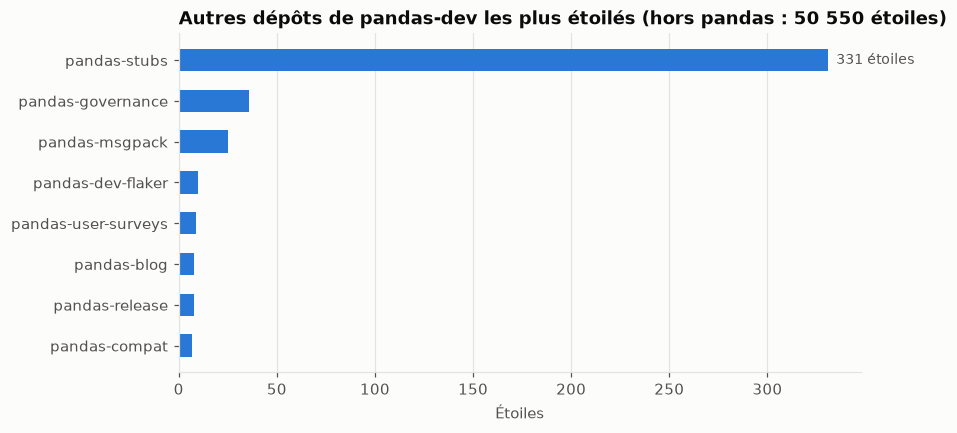

In [3]:
# `pandas` écrase tous les autres dépôts : on le met de côté pour que les autres restent lisibles
phare = repos.nlargest(1, "etoiles").iloc[0]
top = repos.nlargest(9, "etoiles").iloc[1:].sort_values("etoiles")

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top["nom"], top["etoiles"], height=0.55, color=SERIES)
ax.text(top["etoiles"].iloc[-1], len(top) - 1, f"  {top['etoiles'].iloc[-1]} étoiles", va="center", color=MUTED, fontsize=9)
ax.set_title(f"Autres dépôts de pandas-dev les plus étoilés (hors {phare['nom']} : {phare['etoiles']:,} étoiles)".replace(",", " "))
ax.set_xlabel("Étoiles")
ax.grid(axis="y", visible=False)
plt.show()

### Langages utilisés

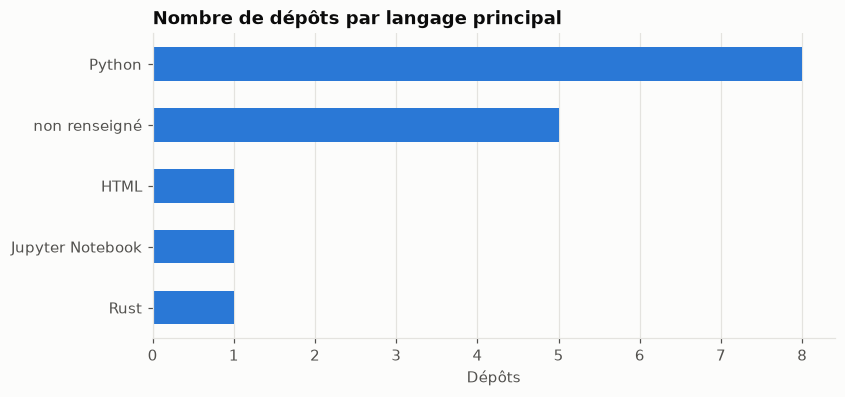

In [4]:
langages = repos["langage"].fillna("non renseigné").value_counts().sort_values()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(langages.index, langages.values, height=0.55, color=SERIES)
ax.set_title("Nombre de dépôts par langage principal")
ax.set_xlabel("Dépôts")
ax.grid(axis="y", visible=False)
plt.show()

In [5]:
save_dataset(repos, "github_pandas_dev", "../data", formats=("csv",))

[WindowsPath('../data/github_pandas_dev.csv')]